In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import cross_val_score
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis 
from sklearn import datasets
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os


In [33]:
data

,gross__magnitude__arm_speed_Gmean,gross__magnitude__arm_speed_peak_mean,gross__variability__arm_speed_peak_std,gross__rhythm__arm_speed_peak_n,gross__rhythm__arm_speed_peak_rate,gross__variability__arm_acc_peak_std,gross__rhythm__arm_acc_peak_n,gross__rhythm__arm_acc_peak_rate,gross__magnitude__arm_speed_integral,gross__rhythm__arm_speed_sampen,...,fine__variability__flexion_speed_std,fine__smoothness__flexion_jerk,fine__coordination__corr_index_middle,fine__coordination__corr_ring_pinky,fine__proxdist__distal_proximal_ratio,fine__variability__flexion_entropy,fileID,group,groupID,concept
0,0.552371,1.377468,0.542730,4,0.851064,2.202244,9,1.914894,2.605717,0.198832,...,0.041215,0.092766,0.463926,0.426655,0.975861,3.073719,GP01_ANSTECKEN,GP01,Gesture,ANSTECKEN
1,1.053819,2.200471,0.711201,4,0.845070,3.229560,9,1.901408,5.005577,0.398639,...,0.272164,-0.495235,0.978735,0.760044,0.850163,2.952784,GP01_BODEN,GP01,Gesture,BODEN
2,0.954794,2.031465,1.121333,4,0.851064,3.622343,11,2.340426,4.503047,0.396464,...,0.612119,0.658854,0.671586,0.855292,1.019093,3.166920,GP01_BRIEF,GP01,Gesture,BRIEF
3,0.385791,1.225327,0.688305,3,0.638298,1.874383,5,1.063830,1.824341,0.091541,...,0.172555,0.212377,0.919347,0.856491,1.034595,2.484640,GP01_BUERO,GP01,Gesture,BUERO
4,0.475486,2.406980,NaN,1,0.212766,3.729381,6,1.276596,2.195847,0.078402,...,0.069693,1.557573,0.945602,0.925923,0.908041,2.567418,GP01_ENTSCHULDIGEN,GP01,Gesture,ENTSCHULDIGEN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
917,0.848801,2.178872,0.700623,2,0.714286,2.016559,4,1.428571,2.390096,0.221237,...,0.194615,1.446838,0.884970,0.812310,0.944186,2.863653,ViCom_98_F_BAPTISM,ViCom,Sign,BAPTISM
918,1.064878,2.707430,0.065215,2,0.909091,2.707563,5,2.272727,2.366977,0.432864,...,0.272743,-2.715291,0.904239,0.950051,0.797826,3.093587,ViCom_98_P_TABLE,ViCom,Sign,TABLE
919,1.171158,1.840424,1.164542,4,1.463415,3.682496,5,1.829268,3.225551,0.365157,...,0.776845,3.642420,0.967153,0.913262,0.835899,3.131641,ViCom_99_F_BIRD,ViCom,Sign,BIRD
920,0.791466,2.451725,0.135782,2,0.666667,0.683709,4,1.333333,2.393711,0.173183,...,0.215581,-1.283285,0.859105,0.780848,27.615500,2.864223,ViCom_99_P_TO-HEAR,ViCom,Sign,TO-HEAR


In [36]:
data = pd.read_csv(os.path.join(os.getcwd(), 'Datasets', 'sampled_sapiens_pruned.csv'))
data.head(20)

# get rid of rows with nan
data = data.dropna()

#define predictor and response variables
## X is all columns except last
X = data.iloc[:, :-5]
y = data['groupID']

#Fit the LDA model
model = LinearDiscriminantAnalysis()
model.fit(X, y)

,solver,'svd'
,shrinkage,None
,priors,None
,n_components,None
,store_covariance,False
,tol,0.0001
,covariance_estimator,None


In [37]:
#Define method to evaluate model
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=1)

#evaluate model
scores = cross_val_score(model, X, y, scoring='accuracy', cv=cv, n_jobs=-1)
print(np.mean(scores))   

0.7756654456654457


0.777 ± 0.038  (chance = 0.273)


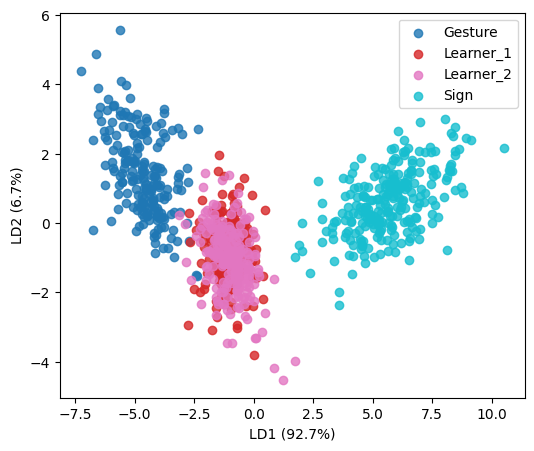

In [39]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

data = pd.read_csv(os.path.join(os.getcwd(), 'Datasets', 'sampled_sapiens_pruned.csv'))
data = data.dropna()

y = data['groupID']
X = data.drop(columns=['groupID']).select_dtypes(include=[np.number])

pipe = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(n_components=2))

cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=1)
scores = cross_val_score(pipe, X, y, scoring='accuracy', cv=cv, n_jobs=-1)
print(f"{scores.mean():.3f} ± {scores.std():.3f}  (chance = {y.value_counts(normalize=True).max():.3f})")

pipe.fit(X, y)

data_plot = pipe.transform(X)
lda = pipe.named_steps['lineardiscriminantanalysis']

# structure coefficients = correlation of each feature with each discriminant
scaler = pipe.named_steps['standardscaler']
X_scaled = scaler.transform(X)
scores_lda = lda.transform(X_scaled)  # (n_samples, n_components)

struct = pd.DataFrame(
    np.corrcoef(X_scaled.T, scores_lda.T)[:X_scaled.shape[1], X_scaled.shape[1]:],
    index=X.columns,
    columns=[f'LD{i+1}' for i in range(scores_lda.shape[1])]
)

y_arr = y.to_numpy()
plt.figure(figsize=(6, 5))
colors = plt.cm.tab10(np.linspace(0, 1, len(lda.classes_)))

for color, cls in zip(colors, lda.classes_):
    m = y_arr == cls
    plt.scatter(data_plot[m, 0], data_plot[m, 1], alpha=.8, color=color, label=cls)
ev = lda.explained_variance_ratio_
plt.xlabel(f"LD1 ({ev[0]:.1%})")
plt.ylabel(f"LD2 ({ev[1]:.1%})")
plt.legend(loc='best', scatterpoints=1)
plt.show()

In [40]:
lda = pipe.named_steps['lineardiscriminantanalysis']
weights = pd.DataFrame(lda.scalings_[:, :2], index=X.columns, columns=['LD1', 'LD2'])
weights.reindex(weights.LD1.abs().sort_values(ascending=False).index).head(15)

,LD1,LD2
gross__smoothness__arm_intermittency,-1.493795,-0.492349
gross__rhythm__arm_acc_peak_n,-1.415792,0.366750
gross__rhythm__arm_acc_peak_rate,1.372424,-0.089036
fine__handshape__handshape_size_mean,-0.990910,1.263590
gross__magnitude__arm_speed_Gmean,0.897277,0.123285
gross__magnitude__arm_speed_integral,-0.810621,0.257864
fine__handshape__mcp_tip_mean,0.507509,-0.506115
gross__rhythm__band3_band_power_totalarm,-0.308295,-0.411754
gross__rhythm__arm_speed_peak_rate,0.308263,0.329860
fine__handshape__thumb_opposition_mean,0.273232,0.149373


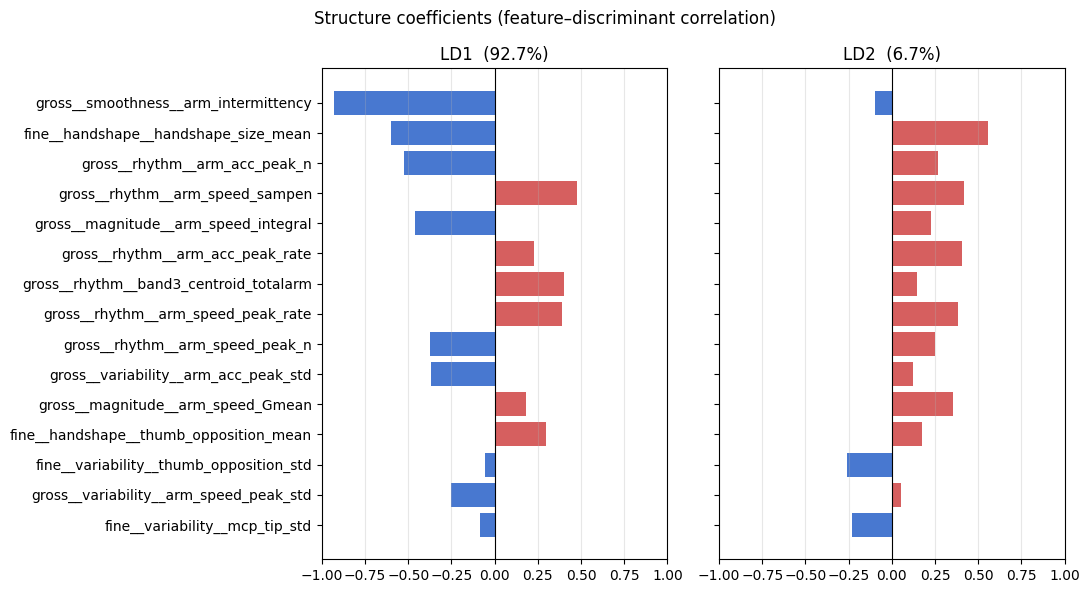

In [41]:
top = struct.reindex(struct.abs().max(axis=1).sort_values(ascending=False).index)[:15][::-1]

fig, axes = plt.subplots(1, 2, figsize=(11, 6), sharey=True)
for ax, ld in zip(axes, ['LD1', 'LD2']):
    v = top[ld]
    ax.barh(top.index, v, color=np.where(v < 0, '#4878d0', '#d65f5f'))
    ax.axvline(0, color='k', lw=.8)
    ax.set_xlim(-1, 1)
    ax.set_title(f"{ld}  ({ev[int(ld[-1])-1]:.1%})")
    ax.grid(axis='x', alpha=.3)
fig.suptitle('Structure coefficients (feature–discriminant correlation)')
plt.tight_layout()

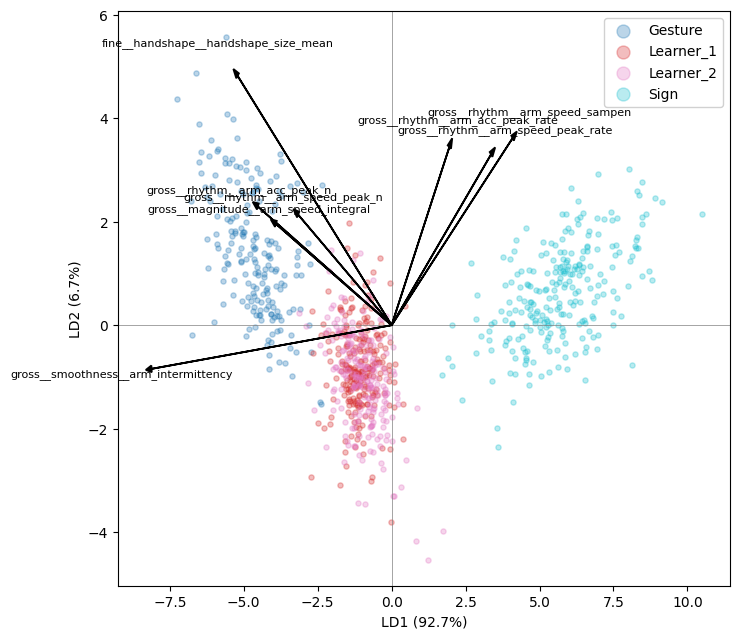

In [42]:
scores_lda = pipe.transform(X)[:, :2]
y_arr = y.to_numpy()
colors = plt.cm.tab10(np.linspace(0, 1, len(lda.classes_)))

fig, ax = plt.subplots(figsize=(7.5, 6.5))
for c, cls in zip(colors, lda.classes_):
    m = y_arr == cls
    ax.scatter(scores_lda[m, 0], scores_lda[m, 1], s=14, alpha=.30, color=c, label=cls)

k = 8
sel = struct[['LD1', 'LD2']].pow(2).sum(1).pow(.5).sort_values(ascending=False).index[:k]
scale = 0.85 * np.abs(scores_lda).max()
for f in sel:
    dx, dy = struct.loc[f, 'LD1'] * scale, struct.loc[f, 'LD2'] * scale
    ax.arrow(0, 0, dx, dy, color='k', lw=1.3, head_width=.13,
             length_includes_head=True, zorder=5)
    ax.text(dx * 1.10, dy * 1.10, f, fontsize=8, ha='center', va='center', zorder=6)

ax.axhline(0, color='grey', lw=.5); ax.axvline(0, color='grey', lw=.5)
ax.set_xlabel(f"LD1 ({ev[0]:.1%})"); ax.set_ylabel(f"LD2 ({ev[1]:.1%})")
ax.legend(markerscale=2.5, framealpha=.9)
plt.tight_layout()

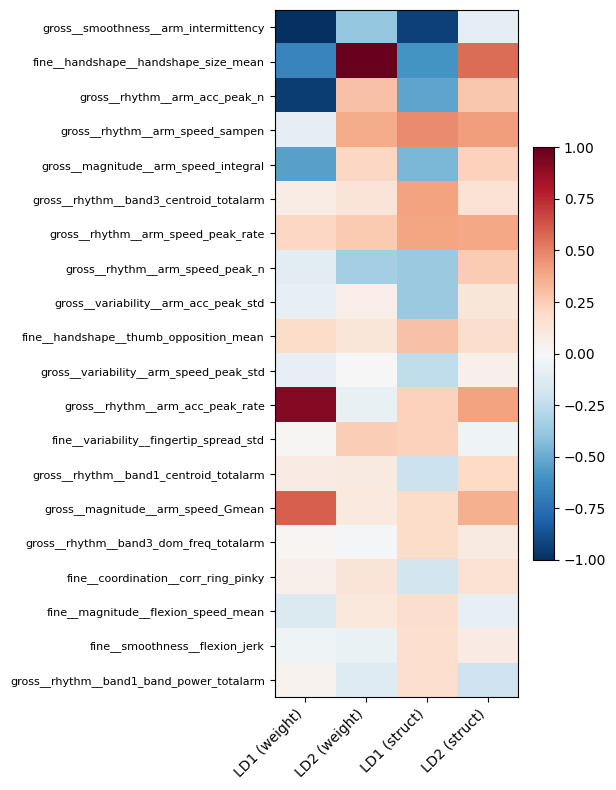

In [43]:
w = weights[['LD1', 'LD2']] / np.abs(weights[['LD1', 'LD2']]).max()   # rescale to compare
comp = pd.concat([w.add_suffix(' (weight)'), struct[['LD1', 'LD2']].add_suffix(' (struct)')], axis=1)
comp = comp.reindex(struct.LD1.abs().sort_values(ascending=False).index)[:20]

fig, ax = plt.subplots(figsize=(6, 8))
lim = np.abs(comp.values).max()
im = ax.imshow(comp.values, cmap='RdBu_r', vmin=-lim, vmax=lim, aspect='auto')
ax.set_xticks(range(comp.shape[1])); ax.set_xticklabels(comp.columns, rotation=45, ha='right')
ax.set_yticks(range(len(comp))); ax.set_yticklabels(comp.index, fontsize=8)
fig.colorbar(im, ax=ax, shrink=.6)
plt.tight_layout()

In [44]:
Xs = pipe.named_steps['standardscaler'].transform(X)
scores_lda = pipe.transform(X)[:, :2]

struct = pd.DataFrame(
    {f'LD{i+1}': [np.corrcoef(Xs[:, j], scores_lda[:, i])[0, 1] for j in range(Xs.shape[1])]
     for i in range(2)},
    index=X.columns)
struct.reindex(struct.LD1.abs().sort_values(ascending=False).index).head(15)

,LD1,LD2
gross__smoothness__arm_intermittency,-0.931707,-0.096932
fine__handshape__handshape_size_mean,-0.599892,0.555505
gross__rhythm__arm_acc_peak_n,-0.526605,0.267212
gross__rhythm__arm_speed_sampen,0.474779,0.419989
gross__magnitude__arm_speed_integral,-0.458334,0.229437
gross__rhythm__band3_centroid_totalarm,0.399530,0.145241
gross__rhythm__arm_speed_peak_rate,0.392351,0.385502
gross__rhythm__arm_speed_peak_n,-0.372534,0.251876
gross__variability__arm_acc_peak_std,-0.368017,0.120631
fine__handshape__thumb_opposition_mean,0.294996,0.174384
